# Relation-aware multi-label contrastive learning on COCO-MLT

Tests whether weighting negatives by label relations in a multi-label
supervised contrastive loss reduces tail-class false positives on
related classes and improves tail mAP. It uses the CLIP features, labels
and text embeddings that `coco_mlt_context_check.ipynb` saved: no
downloads.

**What is compared.** All contrastive variants use the official
**MulSupCon** pipeline (Zhang & Wu, AAAI 2024; settings from the
official repository's vector-data configuration): an MLP encoder on the
frozen CLIP features, a projection head, a momentum key encoder with a
queue, 50% feature masking as augmentation, 150 epochs x 1,000
iterations of contrastive pretraining, then fine-tuning with BCE. The
variants differ **only** in how negatives are weighted inside the loss:

| Variant | Negative weights | Settings tried |
|---|---|---|
| BCE | no contrastive pretraining (the official BCE baseline) | backbone lr x0.1 (official) or x1 |
| MulSupCon | all equal (official loss) | - |
| **+ selective relation weights (ours)** | 1 + alpha x {1 related & seen together, 0.5 related & never together, 0.25 informative companion, 0 otherwise} | alpha 1 or 4 |
| + all-companion weights | 1 + alpha for any label seen with the anchor's label in training (not selective) | alpha 1 or 4 |
| + SCHaNe weights | feature-similarity weights (Long et al. 2023, Eq. 3) | temperature 0.1 or 0.5 |
| + LCL weights | the anchor's predicted probability for the negative's labels, from a weighting network (Suresh & Ong 2021, Eq. 3, adapted to multi-label) | temperature 0.1 or 0.3 |
| BCE + relation weights | the same relation weights on BCE negatives, no contrastive part | alpha 1 or 4; backbone lr x0.1 or x1 |

**Protocol.** Training images are split 80/20 by iterative
stratification. The 80% part is used for training, the 20% part (the
dev set) for early stopping and for choosing each variant's setting
(with seed 42). Every variant is then run with seeds 42, 43 and 44. The
5,000 evaluation images are used only for the final results.
Fine-tuning follows the official rules (stop after 20 epochs without a
lower dev loss; predict with the lowest-dev-loss epoch), but the
official cap of 30 epochs is raised to 400 so that early stopping, not
the cap, ends training: in a test run on stand-in data every variant
was still improving at epoch 30. Results at the official 30-epoch cap
are reported as a secondary check.

**Rules, set before running.** Compared with MulSupCon, the method
**works** if (1) tail AP improves, with a 95% interval above zero
(intervals resample classes) and a higher tail mAP in at least 2 of the
3 seeds, (2) the related-class false-positive gap shrinks, with its
interval below zero under both busy-image controls, and (3) head AP
drops by no more than 1 point on average. **Partly** = (1) or (2) with
(3). The same checks are repeated against the strongest other variant.

## Step 0: setup

In [1]:
import glob
import hashlib
import importlib
import json
import os
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display

if not os.path.exists("context_reliance_check.py"):
    raise SystemExit("Put context_reliance_check.py in the same folder "
                     "as this notebook.")
import context_reliance_check as crc
importlib.reload(crc)
if not hasattr(crc, "related_labels"):
    raise SystemExit("context_reliance_check.py is an older version. "
                     "Replace it with the latest one.")
pd.set_option("display.max_colwidth", None)    # show full table cells
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"numpy {np.__version__}, pandas {pd.__version__}, "
      f"torch {torch.__version__}")
if DEVICE == "cuda":
    props = torch.cuda.get_device_properties(0)
    print(f"Device: {props.name} ({props.total_memory / 2**30:.1f} GB)")
else:
    print(f"Device: CPU (this PyTorch build has CUDA: {torch.version.cuda})")

numpy 2.5.4, pandas 3.1.0, torch 2.11.0+cu130
Device: NVIDIA GeForce RTX 4070 Laptop GPU (8.0 GB)


## Step 1: settings

In [2]:
DATA = "coco_mlt"
OUT = os.path.join(DATA, "contrastive")
SEEDS = [42, 43, 44]
SELECT_SEED = 42          # settings are chosen on this seed's dev results
DEV_FRAC = 0.2            # share of training images used as the dev set
SPLIT_SEED = 0
RELATED_PCT = 5           # related = top 5% most text-similar labels
BOOTSTRAP = 10000
RETRAIN = False           # True reruns everything, ignoring saved runs
WORKERS = "auto"          # trainings run at the same time: "auto" decides
                          # from CPU cores, free memory and GPU memory;
                          # 1 = one at a time inside this notebook
ALLOW_CPU = False         # True lets the full run go ahead without a GPU
QUICK_TEST = False        # True = tiny run to test the code only;
                          # its numbers mean nothing

# (key, name, kind, settings to try). alpha: relation-weight strength;
# tau: temperature (SCHaNe, LCL); lrp: backbone learning-rate
# multiplier for the BCE-only variants (official 0.1 is meant for a
# pretrained backbone, so 1 is also tried for a backbone from scratch)
VARIANTS = [
    ("bce", "BCE (no pretraining)", "bce", [dict(lrp=0.1), dict(lrp=1.0)]),
    ("mulsupcon", "MulSupCon", "uniform", [dict()]),
    ("ours", "MulSupCon + selective relation weights (ours)", "relation",
     [dict(alpha=1.0), dict(alpha=4.0)]),
    ("companions", "MulSupCon + all-companion weights", "companions",
     [dict(alpha=1.0), dict(alpha=4.0)]),
    ("schane", "MulSupCon + SCHaNe weights", "schane",
     [dict(tau=0.1), dict(tau=0.5)]),
    ("lcl", "MulSupCon + LCL weights", "lcl", [dict(tau=0.1), dict(tau=0.3)]),
    ("relbce", "BCE + selective relation weights (no contrast)", "relbce",
     [dict(alpha=a, lrp=l) for a in (1.0, 4.0) for l in (0.1, 1.0)]),
]
NAME = {k: n for k, n, _, _ in VARIANTS}


def setting_text(s):
    words = {"alpha": "alpha {:g}", "tau": "temperature {:g}",
             "lrp": "backbone lr x{:g}"}
    return ", ".join(words[k].format(v) for k, v in s.items()) or "-"


def setting_tag(s):
    return "-".join(f"{k}{v:g}" for k, v in s.items()) or "default"


if DEVICE == "cpu" and not (QUICK_TEST or ALLOW_CPU):
    raise SystemExit(
        "No GPU is visible to this notebook, so the full run would take "
        "well over 10 hours. In Jupyter, use Kernel > Change kernel to pick "
        "the environment you used for the earlier notebooks, then Restart "
        "& Run All. (To run on the CPU anyway, set ALLOW_CPU = True.)")
for sub in ("runs", "backbones", "logs"):
    os.makedirs(os.path.join(OUT, sub), exist_ok=True)
pd.DataFrame([(n, kind, " / ".join(setting_text(s) for s in grid))
              for _, n, kind, grid in VARIANTS],
             columns=["variant", "kind", "settings tried"])

,variant,kind,settings tried
0,BCE (no pretraining),bce,backbone lr x0.1 / backbone lr x1
1,MulSupCon,uniform,-
2,MulSupCon + selective relation weights (ours),relation,alpha 1 / alpha 4
3,MulSupCon + all-companion weights,companions,alpha 1 / alpha 4
4,MulSupCon + SCHaNe weights,schane,temperature 0.1 / temperature 0.5
5,MulSupCon + LCL weights,lcl,temperature 0.1 / temperature 0.3
6,BCE + selective relation weights (no contrast),relbce,"alpha 1, backbone lr x0.1 / alpha 1, backbone lr x1 / alpha 4, backbone lr x0.1 / alpha 4, backbone lr x1"


## Step 2: method code

MulSupCon is reproduced from the official repository (models, loss,
queue, sampler, augmentation, schedules). The other variants only add
negative weights inside the same loss; SCHaNe and LCL are implemented
from their papers' equations (notes at the top of the code). Settings
are the official vector-data ones (`pretrain_yeast.yaml`,
`train_yeast.yaml`) except the fine-tuning cap (see the top); the yeast
training set (~1,500 samples) is about the size of our 80% split
(about 1,520 images). This cell saves the code as
`relation_contrastive_method.py` (the next cell loads it).

In [3]:
%%writefile relation_contrastive_method.py
# ---------------------------------------------------------------------------
# Core code for the relation-aware contrastive experiment (frozen CLIP features)
#
# MulSupCon follows the official implementation (Zhang & Wu, AAAI 2024,
# github: MulSupCon, vector-data configuration): MLP backbone, projection
# head, MoCo-style momentum key encoder and queue, MulSupCon positives (each
# label of an anchor separately), WeightedSupCon loss with 1/len(rows)
# weights, 50% feature masking, Adam + cosine warm restarts, then fine-tuning
# with BCE (backbone lr x0.1, ReduceLROnPlateau, early stopping on a dev set).
# The other variants change only how negatives are weighted inside that loss.
#
# SCHaNe (Long et al. 2023) and LCL (Suresh & Ong 2021) have no official code
# for this setting; their weights are implemented from the papers' equations:
#   SCHaNe Eq. 3: negative k of anchor i gets
#                 beta_k = |N| exp(s_ik/tau) / sum_{n in N} exp(s_in/tau)
#   LCL Eq. 3:    every term of anchor i is weighted by w_{i, y_a}, the
#                 anchor's weighting-network probability for candidate a's
#                 class (w_{i, y_i} for positives, numerator included).
#                 Multi-label adaptation: sigmoid probabilities (BCE-trained
#                 weighting network) and, for a negative with several labels,
#                 the largest of the anchor's probabilities for those labels.
# ---------------------------------------------------------------------------
import copy
import math
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

CODE_VERSION = "2026-10-30"     # part of the saved-run tag (unchanged: same computation)

# Official settings (codes/config/pretrain_yeast.yaml and train_yeast.yaml)
PRETRAIN = dict(epochs=150, iters_per_epoch=1000, batch_size=64, cap_Q=256,
                momentum=0.999, temperature=0.1, out_dim=256, n_hidden=1,
                lr=4e-4, weight_decay=1e-5, T_0=50, T_mult=2, eta_min=1e-4,
                mask_p=0.5, running_alpha=0.98)
# Fine-tuning: official rules (BCE, Adam, backbone lr x0.1, ReduceLROnPlateau,
# early stopping after 20 epochs without a lower dev loss, test predictions
# at the lowest dev loss). One change: the official cap of 30 epochs (set for
# the 14-label yeast data) is raised to max_epochs so that early stopping,
# not the cap, ends training. The official-cap result is read from the same
# run (its first 30 epochs are identical) and reported as a secondary check.
FINETUNE = dict(official_epochs=30, max_epochs=400, iters_per_epoch=50,
                batch_size=32, lr=4e-4, lrp=0.1, plateau_factor=0.1,
                plateau_patience=2, plateau_cooldown=1, plateau_threshold=1e-3,
                early_stop_patience=20)


# --------------------------- data helpers ----------------------------------
def iterative_split(Y, test_frac, seed):
    """Iterative stratification for multi-label data (Sechidis et al., 2011).
    Returns 0 (fit) / 1 (dev) for each row, keeping every label's share close
    to the target in both parts."""
    rng = np.random.default_rng(seed)
    Y = np.asarray(Y, dtype=bool)
    n = Y.shape[0]
    frac = np.array([1.0 - test_frac, test_frac])
    desired = frac * n
    desired_label = np.outer(frac, Y.sum(0)).astype(float)
    remaining = np.ones(n, dtype=bool)
    assign = -np.ones(n, dtype=int)
    while True:
        rem = Y[remaining].sum(0)
        if rem.sum() == 0:
            break
        label = int(np.argmin(np.where(rem > 0, rem, np.iinfo(np.int64).max)))
        idx = np.flatnonzero(remaining & Y[:, label])
        rng.shuffle(idx)
        for i in idx:
            d = desired_label[:, label]
            cand = np.flatnonzero(d == d.max())
            if cand.size > 1:
                ds = desired[cand]
                cand = cand[ds == ds.max()]
            s = int(rng.choice(cand)) if cand.size > 1 else int(cand[0])
            assign[i] = s
            remaining[i] = False
            desired_label[s] -= Y[i]
            desired[s] -= 1
    for i in np.flatnonzero(remaining):          # images without labels
        s = int(np.argmax(desired))
        assign[i] = s
        desired[s] -= 1
    return assign


class Scaler:
    """sklearn.preprocessing.StandardScaler (population std, zero std -> 1)."""

    def fit(self, X):
        self.mean = X.mean(0)
        std = X.std(0)
        self.scale = np.where(std == 0, 1.0, std)
        return self

    def transform(self, X):
        return ((X - self.mean) / self.scale).astype(np.float32)


class OfficialSampler:
    """Batches exactly as the official RandomSampler: indices shuffled once
    by parse_data (RandomState(seed)), again by the sampler (RandomState(seed)),
    then read cyclically, reshuffling each time the pointer wraps."""

    def __init__(self, n, batch_size, seed):
        indices = list(range(n))
        np.random.RandomState(seed=seed).shuffle(indices)     # parse_data
        self.indices = np.array(indices)
        self.rs = np.random.RandomState(seed=seed)            # Sampler
        self.rs.shuffle(self.indices)
        self.ptr, self.batch_size = 0, batch_size

    def next(self):
        out = np.empty(self.batch_size, dtype=np.int64)
        for j in range(self.batch_size):
            out[j] = self.indices[self.ptr]
            self.ptr = (self.ptr + 1) % len(self.indices)
            if not self.ptr:
                self.rs.shuffle(self.indices)
        return out


def mask_views(x, p, generator):
    """Official vector augmentation: each feature kept with probability 1-p."""
    if not p:
        return x
    keep = (torch.rand(x.shape, generator=generator, device=x.device) > p)
    return x * keep.to(x.dtype)


# --------------------------- models (official) ------------------------------
class Backbone(nn.Module):
    """codes/backbone.py: MLP (vector data)."""

    def __init__(self, in_dim, dropout=0.2):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(in_dim, 256), nn.ReLU(), nn.Dropout(p=dropout),
            nn.Linear(256, 512), nn.ReLU(), nn.Dropout(p=dropout),
            nn.Linear(512, 256), nn.ReLU(), nn.Dropout(p=dropout))

    def forward(self, x):
        return self.mlp(x)


class ProjHead(nn.Module):
    """codes/models.py: MLP projection head."""

    def __init__(self, in_dim=256, out_dim=256, n_hidden=1):
        super().__init__()
        layers, d = [], in_dim
        for _ in range(n_hidden):
            nxt = d // 2 if d >= 2 * out_dim else out_dim
            layers += [nn.Linear(d, nxt), nn.BatchNorm1d(nxt), nn.ReLU(),
                       nn.Dropout(p=0.1)]
            d = nxt
        layers.append(nn.Linear(d, out_dim))
        self.mlp = nn.Sequential(*layers)

    def forward(self, x):
        return self.mlp(x)


class Encoder(nn.Module):
    def __init__(self, in_dim, out_dim=256, n_hidden=1):
        super().__init__()
        self.backbone = Backbone(in_dim)
        self.proj_head = ProjHead(256, out_dim, n_hidden)

    def forward(self, x):
        return self.proj_head(self.backbone(x))


class Classifier(nn.Module):
    """codes/models.py 'Simple': backbone + linear output layer."""

    def __init__(self, in_dim, n_class):
        super().__init__()
        self.backbone = Backbone(in_dim)
        self.output_layer = nn.Linear(256, n_class)

    def forward(self, x):
        return self.output_layer(self.backbone(x))


class PretrainModel(nn.Module):
    """codes/models.py PretrainModel (MoCo queue + momentum key encoder)."""

    def __init__(self, in_dim, n_class, cap_Q, momentum, out_dim, n_hidden):
        super().__init__()
        self.encoder_q = Encoder(in_dim, out_dim, n_hidden)
        self.encoder_k = Encoder(in_dim, out_dim, n_hidden)
        self.m, self.cap_Q = momentum, cap_Q
        self.register_buffer("QueuePtr", torch.tensor([0], dtype=torch.int32))
        self.register_buffer("QueueFull", torch.tensor([False]))
        self.register_buffer("MoCoQueue", nn.functional.normalize(
            torch.randn(out_dim, cap_Q), dim=0))
        self.register_buffer("LabelQueue", torch.zeros(cap_Q, n_class))
        for pq, pk in zip(self.encoder_q.parameters(),
                          self.encoder_k.parameters()):
            pk.data.copy_(pq.data)
            pk.requires_grad = False
        self._q = list(self.encoder_q.parameters())
        self._k = list(self.encoder_k.parameters())
        # Queue pointer and 'full' flag kept on the CPU as well, so no GPU
        # synchronisation is needed each step (same values as the buffers).
        self._ptr, self._full = 0, False

    @torch.no_grad()
    def momentum_update(self):
        torch._foreach_mul_(self._k, self.m)
        torch._foreach_add_(self._k, self._q, alpha=1 - self.m)

    def forward(self, x1, x2, labels):
        """Returns (scores, reference labels). Same order of operations as the
        official forward(): momentum update, queries, keys, clone of the
        queue, enqueue, then scores (batch keys only until the queue is
        full, then batch keys + queue)."""
        if self.training:
            self.momentum_update()
        q = nn.functional.normalize(self.encoder_q(x1), dim=1)
        with torch.no_grad():
            k = nn.functional.normalize(self.encoder_k(x2), dim=1)
        queue_k = self.MoCoQueue.clone().detach()
        queue_labels = self.LabelQueue.clone().detach()
        if self.training:
            B = len(labels)
            assert not self.cap_Q % B
            ptr = self._ptr
            self.MoCoQueue[:, ptr:ptr + B] = k.T
            self.LabelQueue[ptr:ptr + B] = labels
            ptr = (ptr + B) % self.cap_Q
            self._ptr = ptr
            self.QueuePtr.fill_(ptr)
            if not ptr:
                self._full = True
                self.QueueFull.fill_(True)
        batch_score = q @ k.T
        if not self._full:
            return batch_score, labels
        scores = torch.cat([batch_score, q @ queue_k], dim=1)
        ref_labels = torch.cat([labels, queue_labels], dim=0)
        return scores, ref_labels


# --------------------------- losses -----------------------------------------
def mulsupcon_loss(scores, batch_labels, ref_labels, tau, mode="uniform",
                   relation=None, alpha=0.0, p_anchor=None):
    """MulSupCon loss with optional negative weights.

    One row per (anchor image, anchor label k), in the official order
    (torch.where on the batch labels). Positives of a row: candidates that
    carry label k (the anchor's own key included). Loss per row:
        -(1/|P|) sum_p log( w_p e^{s_p/tau} / sum_a w_a e^{s_a/tau} )
    averaged over rows (official weights 1/len(rows)). With all w = 1 this is
    exactly the official MulSupCon/WeightedSupCon loss.

    mode:
      uniform    : w = 1 (MulSupCon)
      schane     : negatives w = |N| e^{s/tau} / sum_N e^{s/tau}
                   (Long et al. 2023, Eq. 3), positives 1
      lcl        : LCL Eq. 3 (Suresh & Ong 2021), weights from the anchor's
                   weighting-network probabilities p_anchor (B x C):
                   positives w = p_anchor[i, k] (numerator included),
                   negatives w = max over the candidate's labels c of
                   p_anchor[i, c]
      relation   : negatives w = 1 + alpha * max_c R[k, c] over the
                   candidate's labels c (relation given as list of
                   (value, mask matrix L x L)); positives 1
    """
    img_idx, lab_idx = torch.where(batch_labels == 1)
    logits = scores[img_idx] / tau                        # R x Q
    pos = ref_labels[:, lab_idx].T > 0.5                  # R x Q
    n_pos = pos.sum(1)
    if mode == "uniform":
        log_prob = logits - torch.logsumexp(logits, dim=1, keepdim=True)
    else:
        if mode == "schane":
            masked = logits.masked_fill(pos, float("-inf"))
            n_neg = (~pos).sum(1, keepdim=True).clamp_min(1)
            log_beta = (masked - torch.logsumexp(masked, dim=1, keepdim=True)
                        + torch.log(n_neg.to(logits.dtype)))
            logw = torch.where(pos, torch.zeros_like(logits), log_beta)
        elif mode == "lcl":
            pa = p_anchor[img_idx]                                      # R x C
            w_pos = pa[torch.arange(len(lab_idx)), lab_idx].unsqueeze(1)  # R x 1
            w_cand = (pa.unsqueeze(1) * ref_labels.unsqueeze(0)).amax(2)  # R x Q
            w = torch.where(pos, w_pos.expand_as(logits), w_cand)
            logw = torch.log(w.clamp_min(1e-6))
        elif mode == "relation":
            score = torch.zeros_like(logits)
            refT = ref_labels.T                                         # C x Q
            for value, M in relation:
                has = (M[lab_idx] @ refT) > 0.5                         # R x Q
                score = torch.maximum(score, has.to(logits.dtype) * value)
            logw = torch.where(pos, torch.zeros_like(logits),
                               torch.log1p(alpha * score))
        else:
            raise ValueError(mode)
        z = logits + logw
        log_prob = z - torch.logsumexp(z, dim=1, keepdim=True)
    per_row = -(log_prob * pos).sum(1) / n_pos
    return per_row.mean()


def mulsupcon_loss_vec(scores, batch_labels, ref_labels, tau, mode="uniform",
                       relation=None, alpha=0.0, p_anchor=None):
    """Same loss as mulsupcon_loss, computed for every (anchor, label) pair at
    once with fixed shapes (no data-dependent indexing, so no GPU sync).
    Rows whose label is absent from the anchor are computed and discarded.
    Shapes: scores B x Q, batch_labels B x C, ref_labels Q x C."""
    logits = scores / tau                                   # B x Q
    ref = ref_labels                                        # Q x C (0/1 float)
    refT = ref.T                                            # C x Q
    n_pos = ref.sum(0)                                      # C
    Yb = batch_labels                                       # B x C
    pos_sum = logits @ ref                                  # B x C: sum_p logit_p
    if mode == "uniform":
        den = torch.logsumexp(logits, dim=1, keepdim=True)  # B x 1
        row = -(pos_sum / n_pos.clamp_min(1) - den)         # B x C
    else:
        posmask = refT.unsqueeze(0) > 0.5                   # 1 x C x Q
        if mode == "relation":
            score = torch.zeros_like(refT)                  # C x Q
            for value, M in relation:
                has = (M @ refT) > 0.5                      # C x Q
                score = torch.maximum(score, has.to(logits.dtype) * value)
            lw = torch.where(refT > 0.5, torch.zeros_like(score),
                             torch.log1p(alpha * score))    # C x Q
            z = logits.unsqueeze(1) + lw.unsqueeze(0)       # B x C x Q
            pos_lw = 0.0
        elif mode == "schane":
            L3 = logits.unsqueeze(1).expand(-1, refT.shape[0], -1)
            # finite fill (not -inf) keeps gradients finite for rows without
            # negatives; exp(-1e4) is exactly 0 for the others
            neg_logits = L3.masked_fill(posmask, -1e4)
            n_neg = (refT < 0.5).sum(1).clamp_min(1).to(logits.dtype)  # C
            lse_neg = torch.logsumexp(neg_logits, dim=2, keepdim=True)
            log_beta = L3 - lse_neg + torch.log(n_neg).view(1, -1, 1)
            z = torch.where(posmask, L3, L3 + log_beta)
            pos_lw = 0.0
        elif mode == "lcl":
            lw_pos = torch.log(p_anchor.clamp_min(1e-6))               # B x C
            w_cand = (p_anchor.unsqueeze(1) * ref.unsqueeze(0)).amax(2)  # B x Q
            lw_neg = torch.log(w_cand.clamp_min(1e-6))                 # B x Q
            lw = torch.where(posmask, lw_pos.unsqueeze(2),
                             lw_neg.unsqueeze(1))                      # B x C x Q
            z = logits.unsqueeze(1) + lw
            pos_lw = lw_pos                                            # B x C
        else:
            raise ValueError(mode)
        den = torch.logsumexp(z, dim=2)                                # B x C
        row = -(pos_sum / n_pos.clamp_min(1) + pos_lw - den)
    keep = Yb > 0.5
    return (row * keep).sum() / keep.sum()


def relation_masks(sim, shared, n_train, n_images, related_fn, pct,
                   min_shared=2, lift_min=2.0):
    """Relation types for negative weights, from training labels only.
    Returns masks (L x L) for: related & seen together, related & never
    together, informative companion; plus 'any companion' (seen together)."""
    L = sim.shape[0]
    rel_seen = np.zeros((L, L), bool)
    rel_never = np.zeros((L, L), bool)
    informative = np.zeros((L, L), bool)
    companion = np.zeros((L, L), bool)
    base = n_train / n_images
    for t in range(L):
        related = related_fn(sim[t], t, pct)
        for c in range(L):
            if c == t:
                continue
            k = shared[t, c]
            if k >= 1:
                companion[t, c] = True
            if related[c]:
                (rel_seen if k >= 1 else rel_never)[t, c] = True
            elif k >= min_shared and n_train[t] and base[c]:
                if (k / n_train[t]) / base[c] >= lift_min:
                    informative[t, c] = True
    return rel_seen, rel_never, informative, companion


# --------------------------- official reference (for the self-test) ---------
def official_generate_output_MulSupCon(batch_labels, ref_labels, scores,
                                       with_weight=False):
    """Verbatim logic of codes/utils.py generate_output_MulSupCon."""
    B = len(batch_labels)
    indices = torch.where(batch_labels == 1)
    scores = scores[indices[0]]
    labels = torch.zeros(len(scores), batch_labels.shape[1], device=scores.device)
    labels[range(len(labels)), indices[1]] = 1
    masks = (labels @ ref_labels.T).to(torch.bool)
    n_score_per_sample = batch_labels.sum(dim=1).to(torch.int16).tolist()
    if with_weight:
        weights_per_sample = [1 / (n * B) for n in n_score_per_sample
                              for _ in range(n)]
    else:
        weights_per_sample = [1 / len(scores) for n in n_score_per_sample
                              for _ in range(n)]
    weights_per_sample = torch.tensor(weights_per_sample, device=scores.device,
                                      dtype=torch.float32)
    return scores, [masks.to(torch.long), weights_per_sample]


def official_weighted_supcon(score, ref, temperature=0.1):
    """Verbatim logic of codes/losses.py WeightedSupCon.forward."""
    mask, weight = ref
    num_pos = mask.sum(1)
    loss = - (torch.log((F.softmax(score / temperature, dim=1))) * mask).sum(1) \
        / num_pos
    return (loss * weight).sum()


# --------------------------- training ---------------------------------------
def set_seeds(seed):
    """As the official Runner: torch, numpy and CUDA seeds, deterministic cuDNN."""
    torch.manual_seed(seed)
    np.random.seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True


def pretrain(X, Y, mode, seed, device, cfg=PRETRAIN, relation=None, alpha=0.0,
             tau=None, report=None, epoch_hook=None):
    """Contrastive pretraining with the official MulSupCon schedule.
    X: scaled fit-split features (float tensor on device); Y: float labels.
    Returns the backbone weights at the lowest running training loss (the
    official 'train_best' checkpoint) and the loss history."""
    set_seeds(seed)
    tau = cfg["temperature"] if tau is None else tau
    N, D = X.shape
    C = Y.shape[1]
    gen = torch.Generator(device=device)
    gen.manual_seed(seed)
    model = PretrainModel(D, C, cfg["cap_Q"], cfg["momentum"], cfg["out_dim"],
                          cfg["n_hidden"]).to(device)
    groups = [{"params": model.encoder_q.backbone.parameters(), "lr": cfg["lr"]},
              {"params": model.encoder_q.proj_head.parameters(), "lr": cfg["lr"]}]
    weighting = None
    if mode == "lcl":
        # LCL weighting network: same architecture as the fine-tuning model,
        # trained with its own (here BCE) loss; only its probabilities are
        # used by the contrastive loss (detached).
        weighting = Classifier(D, C).to(device)
        groups.append({"params": weighting.parameters(), "lr": cfg["lr"]})
    opt = torch.optim.Adam(groups, lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
        opt, T_0=cfg["T_0"], T_mult=cfg["T_mult"], eta_min=cfg["eta_min"])
    sampler = OfficialSampler(N, cfg["batch_size"], seed)
    rel = None
    if relation is not None:
        rel = [(v, torch.as_tensor(m, dtype=torch.float32, device=device))
               for v, m in relation]
    best, best_state, history = math.inf, None, []
    t0 = time.time()
    for epoch in range(cfg["epochs"]):
        running = None        # ignite RunningAverage restarts every epoch
        model.train()
        if weighting is not None:
            weighting.train()
        # the epoch's batches, in the official sampler order, sent to the
        # device once (avoids a GPU synchronisation every iteration)
        batches = torch.from_numpy(np.stack(
            [sampler.next() for _ in range(cfg["iters_per_epoch"])])).to(device)
        for it in range(cfg["iters_per_epoch"]):
            idx = batches[it]
            x, y = X[idx], Y[idx]
            x1 = mask_views(x, cfg["mask_p"], gen)
            x2 = mask_views(x, cfg["mask_p"], gen)
            if mode == "lcl":
                logits_w = weighting(x1)                 # anchor's weighting output
                loss_w = F.binary_cross_entropy_with_logits(logits_w, y)
                p_anchor = torch.sigmoid(logits_w).detach()
                scores, ref = model(x1, x2, y)
                loss_c = mulsupcon_loss_vec(scores, y, ref, tau, "lcl",
                                            p_anchor=p_anchor)
                # LCL Eq. 6 with alpha = 0.5; the encoder's own classification
                # term L_e is left out (MulSupCon pretraining is contrastive
                # only; every variant is fine-tuned with BCE afterwards)
                loss = 0.5 * loss_w + 0.5 * loss_c
            else:
                scores, ref = model(x1, x2, y)
                loss = mulsupcon_loss_vec(scores, y, ref, tau, mode,
                                          relation=rel, alpha=alpha)
            opt.zero_grad()
            loss.backward()
            opt.step()
            v = loss.detach()
            running = v if running is None else \
                cfg["running_alpha"] * running + (1 - cfg["running_alpha"]) * v
        sched.step()
        r = float(running)
        if not math.isfinite(r):
            raise FloatingPointError(f"non-finite loss at epoch {epoch + 1}")
        history.append(r)
        if r < best:                       # official ModelCheckpoint 'train_best'
            best = r
            best_state = copy.deepcopy(model.encoder_q.backbone.state_dict())
        if report is not None and ((epoch + 1) % 25 == 0 or epoch == 0):
            report(f"    epoch {epoch + 1:>3}/{cfg['epochs']}: running loss {r:.4f} "
                   f"({time.time() - t0:.0f} s)")
        if epoch_hook is not None:          # lets a worker stop between epochs
            epoch_hook(epoch + 1)
    return best_state, history


def neg_weight_matrix(Ybin, masks, alpha):
    """Relation weights for BCE negatives: 1 + alpha x the largest relation
    value between the class (column) and any label of the image (row)."""
    score = np.zeros(Ybin.shape, dtype=np.float32)
    for value, M in masks:
        has = (Ybin.astype(np.float32) @ M.T.astype(np.float32)) > 0.5
        score = np.maximum(score, value * has)
    return 1.0 + alpha * score


def weighted_bce(logits, y, neg_weights=None):
    """BCEWithLogitsLoss (mean); optional weights on the negative terms."""
    if neg_weights is None:
        return F.binary_cross_entropy_with_logits(logits, y)
    w = torch.where(y > 0.5, torch.ones_like(neg_weights), neg_weights)
    return F.binary_cross_entropy_with_logits(logits, y, weight=w)


def finetune(Xfit, Yfit, Xdev, Ydev, Xtest, seed, device, cfg=FINETUNE,
             backbone_state=None, w_fit=None, w_dev=None, epoch_hook=None):
    """Official 'train' stage: backbone (pretrained or random) + linear layer,
    BCE, Adam (backbone lr x lrp), ReduceLROnPlateau and early stopping on the
    dev loss; test predictions taken at the best dev loss.

    Returns (main, official). Training runs until early stopping or
    cfg['max_epochs']; 'main' is the lowest-dev-loss epoch of the whole run.
    The first cfg['official_epochs'] epochs are exactly the official run, so
    'official' is the lowest-dev-loss epoch among them (identical to 'main'
    when early stopping comes first)."""
    set_seeds(seed)
    D, C = Xfit.shape[1], Yfit.shape[1]
    model = Classifier(D, C).to(device)
    if backbone_state is not None:
        model.backbone.load_state_dict(backbone_state)
    opt = torch.optim.Adam(
        [{"params": model.backbone.parameters(), "lr": cfg["lr"] * cfg["lrp"]},
         {"params": model.output_layer.parameters(), "lr": cfg["lr"]}],
        lr=cfg["lr"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(
        opt, mode="min", factor=cfg["plateau_factor"],
        patience=cfg["plateau_patience"], cooldown=cfg["plateau_cooldown"],
        threshold=cfg["plateau_threshold"])
    sampler = OfficialSampler(len(Xfit), cfg["batch_size"], seed)
    best, bad, official, main = math.inf, 0, None, None
    n_epochs = max(cfg["official_epochs"], cfg["max_epochs"])
    stopped = False
    for epoch in range(n_epochs):
        model.train()
        batches = torch.from_numpy(np.stack(
            [sampler.next() for _ in range(cfg["iters_per_epoch"])])).to(device)
        for it in range(cfg["iters_per_epoch"]):
            idx = batches[it]
            loss = weighted_bce(model(Xfit[idx]), Yfit[idx],
                                None if w_fit is None else w_fit[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            dev_logits = model(Xdev)
            dev_loss = float(weighted_bce(dev_logits, Ydev, w_dev))
        sched.step(dev_loss)
        if dev_loss < best:
            best, bad = dev_loss, 0
            with torch.no_grad():
                main = dict(test_logits=model(Xtest).cpu().numpy(),
                            dev_logits=dev_logits.cpu().numpy(),
                            best_epoch=epoch + 1, dev_loss=dev_loss)
            if epoch < cfg["official_epochs"]:
                official = main
        else:
            bad += 1
            if bad >= cfg["early_stop_patience"]:
                stopped = True
                break
        if epoch_hook is not None:
            epoch_hook(epoch + 1)
    if official is None:
        raise FloatingPointError("fine-tuning never produced a finite dev loss")
    official = dict(official, epochs_run=min(epoch + 1, cfg["official_epochs"]))
    main = dict(main, epochs_run=epoch + 1, stopped_early=stopped,
                final_lr=float(opt.param_groups[1]["lr"]))
    return main, official


Writing relation_contrastive_method.py


**Running code.** Data preparation, one complete run, and running
several runs at once in separate processes. Each run is computed
exactly as it would be on its own; only the scheduling changes. Saved
as `relation_contrastive_runs.py`.

In [4]:
%%writefile relation_contrastive_runs.py
# ---------------------------------------------------------------------------
# Running the experiment: data preparation, one run, and several runs at the
# same time in separate worker processes. Every run is computed exactly as it
# would be on its own (same code, seed and data); only the scheduling differs.
# Small models like this one leave the GPU idle most of the time, so running
# a few trainings side by side shortens the total time.
# ---------------------------------------------------------------------------
import glob
import json
import os
import subprocess
import sys
import time

import numpy as np
import pandas as pd
import torch
from scipy import sparse

import relation_contrastive_method as rcm

MODE_OF = {"uniform": "uniform", "relation": "relation", "companions": "relation",
           "schane": "schane", "lcl": "lcl"}
HEARTBEAT_TIMEOUT = float(os.environ.get("RC_HEARTBEAT_TIMEOUT", 180))  # s without the notebook -> workers stop


def prepare_data(data, dev_frac, split_seed, related_pct, device):
    """Load the saved features and labels, split the training images
    (iterative stratification), scale the features (official StandardScaler,
    fitted on the training part) and build the relation types from the
    training part's labels. The notebook and every worker call this."""
    import context_reliance_check as crc
    IN, FEAT = os.path.join(data, "check_inputs"), os.path.join(data, "features")
    files = {"training labels": os.path.join(IN, "training_positives.npz"),
             "evaluation labels": os.path.join(IN, "val_positives.npz"),
             "label table": os.path.join(IN, "labels.csv"),
             "training features": os.path.join(FEAT, "train_features.npy"),
             "evaluation features": os.path.join(FEAT, "val_features.npy"),
             "text embeddings": os.path.join(FEAT, "label_text_embeddings.npy")}
    missing = [p for p in files.values() if not os.path.exists(p)]
    if missing:
        raise FileNotFoundError("Missing (run coco_mlt_context_check.ipynb first): "
                                + ", ".join(missing))
    Y_all = sparse.load_npz(files["training labels"]).toarray().astype(np.float32)
    Y_test = np.load(files["evaluation labels"])["positives"].astype(np.float32)
    X_all = np.load(files["training features"]).astype(np.float32)
    X_test = np.load(files["evaluation features"]).astype(np.float32)
    labels_df = pd.read_csv(files["label table"])
    names = labels_df["display_name"].tolist()
    cohort = labels_df["cohort"].to_numpy()
    L = len(names)
    assert X_all.shape[0] == Y_all.shape[0] and X_test.shape[0] == Y_test.shape[0]
    assert Y_all.shape[1] == Y_test.shape[1] == L
    sim = crc.text_similarity(files["text embeddings"], None, L)
    split = rcm.iterative_split(Y_all, dev_frac, split_seed)       # 0 fit, 1 dev
    fit, dev = np.flatnonzero(split == 0), np.flatnonzero(split == 1)
    Y_fit, Y_dev = Y_all[fit], Y_all[dev]
    if (Y_fit.sum(0) == 0).any():
        raise ValueError("A class has no training image after the split.")
    scaler = rcm.Scaler().fit(X_all[fit])
    t = lambda a: torch.as_tensor(a, dtype=torch.float32, device=device)
    shared_fit = Y_fit.T.astype(np.int64) @ Y_fit.astype(np.int64)
    rel_seen, rel_never, informative, companion = rcm.relation_masks(
        sim, shared_fit, np.diag(shared_fit).copy(), len(fit), crc.related_labels,
        related_pct)
    return dict(Y_all=Y_all, Y_test=Y_test, names=names, cohort=cohort, L=L, sim=sim,
                fit=fit, dev=dev, Y_fit=Y_fit, Y_dev=Y_dev,
                Xf=t(scaler.transform(X_all[fit])), Xd=t(scaler.transform(X_all[dev])),
                Xt=t(scaler.transform(X_test)), Yf=t(Y_fit), Yd=t(Y_dev),
                rel_seen=rel_seen, rel_never=rel_never, informative=informative,
                companion=companion,
                RELATION=[(1.0, rel_seen), (0.5, rel_never), (0.25, informative)],
                COMPANION=[(1.0, companion)])


def pretrain_kwargs(kind, setting, D):
    relation = (D["RELATION"] if kind == "relation" else
                D["COMPANION"] if kind == "companions" else None)
    return dict(mode=MODE_OF[kind], relation=relation,
                alpha=setting.get("alpha", 0.0), tau=setting.get("tau"))


def dev_map(logits, Y_dev):
    import context_reliance_check as crc
    aps = [crc.average_precision(logits[:, j], Y_dev[:, j])
           for j in range(Y_dev.shape[1]) if Y_dev[:, j].any()]
    return 100 * float(np.mean(aps))


def run_spec(spec, D, pt_cfg, ft_cfg, device, report=None, epoch_hook=None):
    """One run: contrastive pretraining (contrastive kinds only), then
    fine-tuning. Returns the fields that are saved for the run."""
    kind, setting, seed = spec["kind"], spec["setting"], spec["seed"]
    t0 = time.time()
    history = np.zeros(0)
    ft = dict(ft_cfg, lrp=setting.get("lrp", ft_cfg["lrp"]))
    if kind in ("bce", "relbce"):
        w_fit = w_dev = None
        if kind == "relbce":
            tt = lambda a: torch.as_tensor(a, dtype=torch.float32, device=device)
            w_fit = tt(rcm.neg_weight_matrix(D["Y_fit"], D["RELATION"], setting["alpha"]))
            w_dev = tt(rcm.neg_weight_matrix(D["Y_dev"], D["RELATION"], setting["alpha"]))
        main, cap = rcm.finetune(D["Xf"], D["Yf"], D["Xd"], D["Yd"], D["Xt"], seed,
                                 device, ft, None, w_fit, w_dev, epoch_hook=epoch_hook)
    else:
        state, hist = rcm.pretrain(D["Xf"], D["Yf"], seed=seed, device=device,
                                   cfg=pt_cfg, report=report, epoch_hook=epoch_hook,
                                   **pretrain_kwargs(kind, setting, D))
        if spec.get("backbone_path"):
            torch.save(state, spec["backbone_path"])
        history = np.array(hist)
        main, cap = rcm.finetune(D["Xf"], D["Yf"], D["Xd"], D["Yd"], D["Xt"], seed,
                                 device, ft, backbone_state=state,
                                 epoch_hook=epoch_hook)
    return dict(test_logits=main["test_logits"], dev_logits=main["dev_logits"],
                best_epoch=main["best_epoch"], epochs_run=main["epochs_run"],
                stopped_early=main["stopped_early"], final_lr=main["final_lr"],
                dev_loss=main["dev_loss"], dev_map=dev_map(main["dev_logits"], D["Y_dev"]),
                test_logits_30=cap["test_logits"], best_epoch_30=cap["best_epoch"],
                dev_map_30=dev_map(cap["dev_logits"], D["Y_dev"]),
                history=history, seconds=time.time() - t0)


def save_run(path, out):
    """Write to a temporary file first, so a half-written run never counts."""
    tmp = path[:-len(".npz")] + f".tmp{os.getpid()}.npz"
    np.savez(tmp, **out)
    os.replace(tmp, path)


def load_run(path):
    with np.load(path) as f:
        return {k: f[k] for k in f.files}


def _sync(device):
    if device == "cuda":
        torch.cuda.synchronize()


def _touch(path):
    with open(path, "a"):
        pass
    os.utime(path, None)


def _alive(heartbeat):
    try:
        return time.time() - os.path.getmtime(heartbeat) < HEARTBEAT_TIMEOUT
    except OSError:
        return False


class NotebookStopped(RuntimeError):
    pass


def worker_main(job_path, worker_id):
    """Entry point of a worker process: claims runs one at a time (a lock
    file per run), computes and saves them, and stops if the notebook stops."""
    with open(job_path, encoding="utf-8") as f:
        job = json.load(f)
    torch.set_num_threads(1)
    device, hb = job["device"], job["heartbeat"]
    D = prepare_data(job["data"], job["dev_frac"], job["split_seed"],
                     job["related_pct"], device)

    def hook(_epoch):
        if not _alive(hb):
            raise NotebookStopped("the notebook stopped; this worker exits")

    if job.get("benchmark"):
        b = job["benchmark"]
        cfg = dict(job["pt"], epochs=1, iters_per_epoch=20)
        kw = pretrain_kwargs("uniform", {}, D)
        rcm.pretrain(D["Xf"], D["Yf"], seed=0, device=device, cfg=cfg, **kw)  # warm-up
        _sync(device)
        open(os.path.join(b["dir"], f"ready{worker_id}"), "w").close()
        t_wait = time.time()                  # start timing together
        while (len(glob.glob(os.path.join(b["dir"], "ready*"))) < b["workers"]
               and time.time() - t_wait < 300):
            time.sleep(0.1)
        t0 = time.time()
        rcm.pretrain(D["Xf"], D["Yf"], seed=0, device=device,
                     cfg=dict(cfg, iters_per_epoch=b["iters"]), **kw)
        _sync(device)
        with open(os.path.join(b["dir"], f"result{worker_id}.json"), "w") as f:
            json.dump({"seconds_per_iter": (time.time() - t0) / b["iters"]}, f)
        return
    for spec in job["specs"]:
        if not _alive(hb):
            print("the notebook stopped; this worker exits", flush=True)
            return
        path = spec["path"]
        if os.path.exists(path):
            continue
        lock = path + ".lock"
        try:
            os.close(os.open(lock, os.O_CREAT | os.O_EXCL | os.O_WRONLY))
        except FileExistsError:
            continue                          # another worker has this run
        try:
            print(f"[worker {worker_id}] started {spec['tag']}", flush=True)
            out = run_spec(spec, D, job["pt"], job["ft"], device, epoch_hook=hook)
            save_run(path, out)
            print(f"[worker {worker_id}] finished {spec['tag']} "
                  f"({out['seconds'] / 60:.1f} min)", flush=True)
        except NotebookStopped as e:
            print(str(e), flush=True)
            return
        finally:
            try:
                os.remove(lock)
            except OSError:
                pass


def _launch(job_path, n, log_dir, prefix):
    procs = []
    flags = getattr(subprocess, "CREATE_NO_WINDOW", 0)      # no console windows on Windows
    for w in range(n):
        log = open(os.path.join(log_dir, f"{prefix}{w}.log"), "w", encoding="utf-8")
        code = (f"import relation_contrastive_runs as r; "
                f"r.worker_main({os.path.abspath(job_path)!r}, {w})")
        p = subprocess.Popen([sys.executable, "-u", "-c", code], stdout=log,
                             stderr=subprocess.STDOUT, cwd=os.getcwd(),
                             env=dict(os.environ, PYTHONIOENCODING="utf-8"),
                             creationflags=flags)
        procs.append((p, log))
    return procs


def _stop(procs):
    for p, _ in procs:
        if p.poll() is None:
            p.terminate()
    for p, log in procs:
        try:
            p.wait(timeout=15)
        except subprocess.TimeoutExpired:
            p.kill()
        log.close()


def _log_tail(log_dir, prefix, w, n=25):
    try:
        with open(os.path.join(log_dir, f"{prefix}{w}.log"), encoding="utf-8",
                  errors="replace") as f:
            return "".join(f.readlines()[-n:])
    except OSError:
        return "(no log)"


def benchmark_parallel(n, job, out_dir, iters=300, timeout=900):
    """Seconds per pretraining iteration when n workers train at the same
    time (uniform loss), or None if the workers could not run."""
    log_dir = os.path.join(out_dir, "logs")
    bdir = os.path.join(log_dir, "benchmark")
    os.makedirs(bdir, exist_ok=True)
    for f in glob.glob(os.path.join(bdir, "*")):
        os.remove(f)
    job = dict(job, specs=[], benchmark=dict(workers=n, dir=os.path.abspath(bdir),
                                             iters=iters))
    path = os.path.join(out_dir, "job_benchmark.json")
    with open(path, "w", encoding="utf-8") as f:
        json.dump(job, f)
    _touch(job["heartbeat"])
    procs = _launch(path, n, log_dir, "benchmark_worker")
    t0 = time.time()
    try:
        while any(p.poll() is None for p, _ in procs) and time.time() - t0 < timeout:
            _touch(job["heartbeat"])
            time.sleep(1)
    finally:
        _stop(procs)
    res = []
    for w in range(n):
        try:
            with open(os.path.join(bdir, f"result{w}.json")) as f:
                res.append(json.load(f)["seconds_per_iter"])
        except OSError:
            print(f"Worker {w} did not finish the speed test:\n"
                  + _log_tail(log_dir, "benchmark_worker", w))
    return float(np.mean(res)) if len(res) == n else None


def available_ram_gb():
    """Free system memory in GB, or None if it cannot be read."""
    try:
        import psutil
        return psutil.virtual_memory().available / 2**30
    except Exception:
        pass
    if os.name == "nt":
        try:
            import ctypes

            class _MemStatus(ctypes.Structure):
                _fields_ = [("dwLength", ctypes.c_ulong), ("dwMemoryLoad", ctypes.c_ulong),
                            ("ullTotalPhys", ctypes.c_ulonglong),
                            ("ullAvailPhys", ctypes.c_ulonglong),
                            ("ullTotalPageFile", ctypes.c_ulonglong),
                            ("ullAvailPageFile", ctypes.c_ulonglong),
                            ("ullTotalVirtual", ctypes.c_ulonglong),
                            ("ullAvailVirtual", ctypes.c_ulonglong),
                            ("ullAvailExtendedVirtual", ctypes.c_ulonglong)]

            ms = _MemStatus()
            ms.dwLength = ctypes.sizeof(_MemStatus)
            if ctypes.windll.kernel32.GlobalMemoryStatusEx(ctypes.byref(ms)):
                return ms.ullAvailPhys / 2**30
        except Exception:
            pass
    try:
        with open("/proc/meminfo") as f:
            for line in f:
                if line.startswith("MemAvailable:"):
                    return int(line.split()[1]) / 2**20
    except OSError:
        pass
    return None


def auto_workers(device, ram_per_worker=1.2, vram_per_worker=0.75, cap=4):
    """How many trainings to run at once, limited by CPU cores, free memory
    and GPU memory. Returns (number, explanation)."""
    cores = os.cpu_count() or 2
    limits = {"CPU cores": max(1, cores // 2)}
    parts = [f"{cores} CPU threads"]
    ram = available_ram_gb()
    if ram is not None:
        limits["free memory"] = int((ram - 1.0) // ram_per_worker)
        parts.append(f"{ram:.1f} GB memory free")
    if device == "cuda":
        vram = torch.cuda.get_device_properties(0).total_memory / 2**30
        limits["GPU memory"] = int((vram - 1.0) // vram_per_worker)
        parts.append(f"{vram:.1f} GB GPU memory")
    n = max(1, min(cap, *limits.values()))
    text = ", ".join(parts) + f" -> up to {n} training(s) at once"
    if n < cap and limits.get("free memory", cap) == min(limits.values()):
        text += (" (limited by free memory: close other programs and other "
                 "notebooks' kernels, then rerun this cell, to allow more)")
    return n, text


def makespan(costs, n):
    """Finishing time when jobs (longest first) go to whichever of n workers
    is free first."""
    loads = [0.0] * max(1, n)
    for c in sorted(costs, reverse=True):
        loads[loads.index(min(loads))] += c
    return max(loads)


def execute(specs, workers, job, D, describe, cost, report=print):
    """Compute every run in specs whose result is not saved yet: one by one in
    this process (workers <= 1) or in parallel worker processes."""
    todo = [s for s in specs if not os.path.exists(s["path"])]
    if not todo:
        return
    todo.sort(key=lambda s: -cost[s["tag"]])       # longest first balances workers
    total = sum(cost[s["tag"]] for s in todo)
    state = dict(done=0.0, n=0, t0=time.time())

    def progress(s, out):
        state["done"] += cost[s["tag"]]
        state["n"] += 1
        el = time.time() - state["t0"]
        left = el / state["done"] * (total - state["done"]) if state["done"] else 0
        report(f"  [{state['n']}/{len(todo)}] {describe(s, out)}"
               + (f"; about {left / 60:.0f} min left in this phase"
                  if state["n"] < len(todo) else ""))

    if workers <= 1:
        for s in todo:
            out = run_spec(s, D, job["pt"], job["ft"], job["device"], report=report)
            save_run(s["path"], out)
            progress(s, out)
        return
    run_dir = os.path.dirname(todo[0]["path"])
    for f in (glob.glob(os.path.join(run_dir, "*.lock"))
              + glob.glob(os.path.join(run_dir, "*.tmp*.npz"))):
        os.remove(f)                       # left over from an interrupted session
    out_dir = os.path.dirname(run_dir)
    log_dir = os.path.join(out_dir, "logs")
    os.makedirs(log_dir, exist_ok=True)
    path = os.path.join(out_dir, "job.json")
    with open(path, "w", encoding="utf-8") as f:
        json.dump(dict(job, specs=todo), f)
    _touch(job["heartbeat"])
    n = min(workers, len(todo))
    procs = _launch(path, n, log_dir, "worker")
    reported = set()
    last_note = [time.time()]

    def sweep():
        for s in todo:
            if s["tag"] not in reported and os.path.exists(s["path"]):
                reported.add(s["tag"])
                last_note[0] = time.time()
                progress(s, load_run(s["path"]))

    try:
        while any(p.poll() is None for p, _ in procs):
            _touch(job["heartbeat"])
            sweep()
            if time.time() - last_note[0] > 600:
                last_note[0] = time.time()
                report(f"  ... still running ({(time.time() - state['t0']) / 60:.0f} min "
                       f"into this phase; {len(reported)} of {len(todo)} runs finished)")
            time.sleep(5)
        sweep()
    finally:
        _stop(procs)                       # also on an interrupt: no orphan workers
    missing = [s for s in todo if not os.path.exists(s["path"])]
    if missing:
        for w, (p, _) in enumerate(procs):
            if p.returncode:
                print(f"--- worker {w} stopped with an error; end of its log:\n"
                      + _log_tail(log_dir, "worker", w))
        raise RuntimeError(
            f"{len(missing)} run(s) did not finish (see above). Run this cell again "
            "to continue; finished runs are kept. If a worker ran out of GPU memory, "
            "set WORKERS lower in Step 1.")


Writing relation_contrastive_runs.py


In [5]:
import relation_contrastive_method as rcm
import relation_contrastive_runs as rcr
importlib.reload(rcm)
importlib.reload(rcr)
from relation_contrastive_method import *

PT_CFG, FT_CFG = dict(PRETRAIN), dict(FINETUNE)
if QUICK_TEST:
    PT_CFG.update(epochs=3, iters_per_epoch=40)
    FT_CFG.update(official_epochs=3, max_epochs=6, iters_per_epoch=10)
    print("QUICK_TEST is on: tiny runs, results are meaningless.")
print("Loaded the method code (official MulSupCon model, queue, sampler and "
      "loss, and the weighted variants) and the running code.")
pd.DataFrame({"pretraining": pd.Series(PT_CFG, dtype=object),
              "fine-tuning": pd.Series(FT_CFG, dtype=object)}).fillna("")

Loaded the method code (official MulSupCon model, queue, sampler and loss, and the weighted variants) and the running code.


,pretraining,fine-tuning
T_0,50,
T_mult,2,
batch_size,64,32
cap_Q,256,
early_stop_patience,,20
epochs,150,
eta_min,0.0001,
iters_per_epoch,1000,50
lr,0.0004,0.0004
lrp,,0.1


## Step 3: self-test against the official code

The official MulSupCon functions (`generate_output_MulSupCon` and
`WeightedSupCon`, copied verbatim into the method code) and the loss
used here must give the same values and gradients. Weighted variants
with all weights equal to 1 must reduce to MulSupCon, and the fast
versions of the weighted losses must equal their row-by-row
definitions.

In [6]:
torch.manual_seed(0)


def _labels(n, C, p):
    Yr = (torch.rand(n, C) < p).float()
    Yr[Yr.sum(1) == 0, 0] = 1
    return Yr


results = []
for trial in range(3):
    bl = _labels(64, 80, 0.08)
    ref = torch.cat([bl, _labels(256, 80, 0.05)])
    base = torch.rand(64, 320) * 2 - 1
    s1, s2 = base.clone().requires_grad_(), base.clone().requires_grad_()
    sc, mref = official_generate_output_MulSupCon(bl, ref, s1)
    l1 = official_weighted_supcon(sc, mref, 0.1)
    l2 = mulsupcon_loss_vec(s2, bl, ref, 0.1, "uniform")
    l1.backward()
    l2.backward()
    results.append(("MulSupCon loss and gradients equal the official code",
                    abs(l1.item() - l2.item()) < 1e-5
                    and torch.allclose(s1.grad, s2.grad, atol=1e-6)))
    l3 = mulsupcon_loss_vec(base, bl, ref, 0.1, "relation",
                            relation=[(1.0, torch.ones(80, 80))], alpha=0.0)
    l4 = mulsupcon_loss_vec(base, bl, ref, 0.1, "lcl",
                            p_anchor=torch.ones(64, 80))
    results.append(("relation and LCL weights of 1 give MulSupCon",
                    abs(l3.item() - l2.item()) < 1e-5
                    and abs(l4.item() - l2.item()) < 1e-5))
    for mode, kw in (("schane", {}),
                     ("relation", dict(relation=[(1.0, (torch.rand(80, 80)
                                                        < 0.05).float())],
                                       alpha=3.0)),
                     ("lcl", dict(p_anchor=torch.rand(64, 80)))):
        a = mulsupcon_loss(base, bl, ref, 0.5, mode, **kw).item()
        b = mulsupcon_loss_vec(base, bl, ref, 0.5, mode, **kw).item()
        results.append((f"{mode}: fast loss equals the row-by-row "
                        f"definition", abs(a - b) < 1e-4))
m = PretrainModel(512, 80, 256, 0.999, 256, 1)
m.train()
widths = [m(torch.randn(64, 512), torch.randn(64, 512),
            _labels(64, 80, 0.05))[0].shape[1] for _ in range(5)]
results.append(("queue: batch keys only until full, then batch + queue",
                widths == [64, 64, 64, 320, 320]))
check = pd.DataFrame(results, columns=["check", "passed"]) \
    .groupby("check", sort=False)["passed"].all().reset_index()
if not check["passed"].all():
    display(check)
    raise SystemExit("Self-test failed: do not trust the results.")
check

,check,passed
0,MulSupCon loss and gradients equal the official code,True
1,relation and LCL weights of 1 give MulSupCon,True
2,schane: fast loss equals the row-by-row definition,True
3,relation: fast loss equals the row-by-row definition,True
4,lcl: fast loss equals the row-by-row definition,True
5,"queue: batch keys only until full, then batch + queue",True


## Step 4: data, split and relation types

In [7]:
try:
    D = rcr.prepare_data(DATA, DEV_FRAC, SPLIT_SEED, RELATED_PCT, DEVICE)
except FileNotFoundError as e:
    raise SystemExit(str(e))
Y_all, Y_test, names, cohort, L, sim = (
    D[k] for k in ("Y_all", "Y_test", "names", "cohort", "L", "sim"))
Y_fit, Y_dev, Xf, Xd, Xt, Yf, Yd = (
    D[k] for k in ("Y_fit", "Y_dev", "Xf", "Xd", "Xt", "Yf", "Yd"))
np.savez(os.path.join(OUT, "split.npz"), fit=D["fit"], dev=D["dev"])
JOB = dict(pt=PT_CFG, ft=FT_CFG, device=DEVICE, data=DATA, dev_frac=DEV_FRAC,
           split_seed=SPLIT_SEED, related_pct=RELATED_PCT,
           heartbeat=os.path.abspath(os.path.join(OUT, "runs", "heartbeat")))
rows = []
for g in ("head", "medium", "tail"):
    cols = np.flatnonzero(cohort == g)
    rows.append(dict(cohort=g, classes=len(cols),
                     fit_images_min=int(Y_fit[:, cols].sum(0).min()),
                     dev_images_min=int(Y_dev[:, cols].sum(0).min()),
                     related_seen=int(D["rel_seen"][cols].sum()),
                     related_never=int(D["rel_never"][cols].sum()),
                     informative=int(D["informative"][cols].sum()),
                     any_companion=int(D["companion"][cols].sum())))
print(f"Training images: {len(D['fit'])} for training, {len(D['dev'])} for "
      f"the dev set (stratified); evaluation images: {len(Y_test)}")
print("Relation pairs per cohort (from the training part only):")
pd.DataFrame(rows)

Training images: 1516 for training, 393 for the dev set (stratified); evaluation images: 5000
Relation pairs per cohort (from the training part only):


,cohort,classes,fit_images_min,dev_images_min,related_seen,related_never,informative,any_companion
0,head,22,80,20,79,9,166,1116
1,medium,33,16,4,72,60,159,836
2,tail,25,5,1,23,77,44,242


## Step 5: speed check

In [8]:
def _sync():
    if DEVICE == "cuda":
        torch.cuda.synchronize()


CFG_TAG = hashlib.md5(json.dumps(
    dict(pt=PT_CFG, ft=FT_CFG, split=SPLIT_SEED, dev=DEV_FRAC,
         pct=RELATED_PCT, code=CODE_VERSION), sort_keys=True)
    .encode()).hexdigest()[:8]
OTHERS = [s for s in SEEDS if s != SELECT_SEED]
N_RUNS = sum(len(g) + len(OTHERS) for _, _, _, g in VARIANTS)
SPEED_KEY = {"uniform": "uniform", "relation": "relation",
             "companions": "relation", "schane": "schane", "lcl": "lcl"}
saved = 0 if RETRAIN else len(glob.glob(os.path.join(OUT, "runs",
                                                     f"*_{CFG_TAG}.npz")))
if saved >= N_RUNS:
    speed, ft_epoch, WORKERS = dict.fromkeys(SPEED_KEY.values(), 1.0), 1.0, 1
    print(f"All {N_RUNS} runs are already saved, so the speed test is skipped.")
else:
    speed = {}
    for kind, setting in (("uniform", {}), ("relation", dict(alpha=1.0)),
                          ("schane", dict(tau=0.1)), ("lcl", dict(tau=0.1))):
        kw = rcr.pretrain_kwargs(kind, setting, D)
        cfg = dict(PT_CFG, epochs=1, iters_per_epoch=150)
        pretrain(Xf, Yf, seed=0, device=DEVICE,
                 cfg=dict(cfg, iters_per_epoch=20), **kw)     # warm-up
        _sync()
        t0 = time.time()
        pretrain(Xf, Yf, seed=0, device=DEVICE, cfg=cfg, **kw)
        _sync()
        speed[kind] = (time.time() - t0) / 150
    probe = dict(FT_CFG, official_epochs=4, max_epochs=4)
    finetune(Xf, Yf, Xd, Yd, Xt, 0, DEVICE, dict(probe, official_epochs=1,
                                                 max_epochs=1))  # warm-up
    _sync()
    t0 = time.time()
    finetune(Xf, Yf, Xd, Yd, Xt, 0, DEVICE, probe)
    _sync()
    ft_epoch = (time.time() - t0) / 4
ITERS = PT_CFG["epochs"] * PT_CFG["iters_per_epoch"]


def run_minutes(kind, slowdown=1.0):
    pt = speed[SPEED_KEY[kind]] * ITERS if kind in SPEED_KEY else 0.0
    return slowdown * (pt + ft_epoch * FT_CFG["max_epochs"]) / 60


PHASE1 = ([kind for _, _, kind, g in VARIANTS for _ in g]
          + [kind for _, _, kind, g in VARIANTS if len(g) == 1 for _ in OTHERS])
PHASE2 = [kind for _, _, kind, g in VARIANTS if len(g) > 1 for _ in OTHERS]
if saved < N_RUNS:
    serial = sum(run_minutes(k) for k in PHASE1 + PHASE2)
    estimate = serial
    if WORKERS == "auto":
        WORKERS, info = rcr.auto_workers(DEVICE)
        print(info)
    WORKERS = int(WORKERS)
    if WORKERS > 1:
        print(f"Testing {WORKERS} trainings at the same time (about a minute)...")
        t_par = rcr.benchmark_parallel(WORKERS, JOB, OUT)
        if t_par is None:
            print("The parallel test failed (see above), so trainings will "
                  "run one at a time.")
            WORKERS = 1
        else:
            slow = t_par / speed["uniform"]
            par = (rcr.makespan([run_minutes(k, slow) for k in PHASE1], WORKERS)
                   + rcr.makespan([run_minutes(k, slow) for k in PHASE2], WORKERS))
            if par < 0.9 * serial:
                print(f"With {WORKERS} at once each training runs {slow:.1f}x "
                      f"slower, but the total is shorter.")
                estimate = par
            else:
                print(f"Running {WORKERS} at once is not faster here (each "
                      f"training runs {slow:.1f}x slower), so trainings will "
                      f"run one at a time.")
                WORKERS = 1
    print(f"Estimated time: up to about {estimate:.0f} min ({estimate / 60:.1f} h)"
          f" for all {N_RUNS} runs, {WORKERS} at a time (one at a time it would "
          f"be up to {serial / 60:.1f} h). Saved runs are skipped.")
    display(pd.DataFrame({
        "ms per iteration": {k: round(1000 * v, 2) for k, v in speed.items()},
        "minutes per pretraining run (alone)":
            {k: round(v * ITERS / 60, 1) for k, v in speed.items()},
        "pretraining runs": {k: sum(SPEED_KEY.get(x) == k for x in PHASE1 + PHASE2)
                             for k in speed}}))

16 CPU threads, 3.6 GB memory free, 8.0 GB GPU memory -> up to 2 training(s) at once (limited by free memory: close other programs and other notebooks' kernels, then rerun this cell, to allow more)
Testing 2 trainings at the same time (about a minute)...
With 2 at once each training runs 0.8x slower, but the total is shorter.
Estimated time: up to about 268 min (4.5 h) for all 29 runs, 2 at a time (one at a time it would be up to 10.7 h). Saved runs are skipped.


,ms per iteration,minutes per pretraining run (alone),pretraining runs
uniform,12.65,31.6,3
relation,12.32,30.8,8
schane,12.70,31.7,4
lcl,13.19,33.0,4


## Step 6: run every variant (resumable)

Phase 1 runs every setting with seed 42 (plus MulSupCon's other seeds,
which need no choice). For each variant, the setting with the higher
dev mAP (all classes, dev images only) is kept, and phase 2 runs it
with seeds 43 and 44. 

In [9]:
def make_spec(key, kind, setting, seed):
    tag = f"{key}_{setting_tag(setting)}_{seed}_{CFG_TAG}"
    return dict(key=key, kind=kind, setting=setting, seed=seed, tag=tag,
                path=os.path.abspath(os.path.join(OUT, "runs", tag + ".npz")),
                backbone_path=os.path.abspath(
                    os.path.join(OUT, "backbones", tag + ".pt")))


def describe(s, r):
    return (f"{NAME[s['key']]}, {setting_text(s['setting'])}, seed "
            f"{s['seed']}: dev mAP {float(r['dev_map']):.2f}; fine-tuning best "
            f"epoch {int(r['best_epoch'])} of {int(r['epochs_run'])} "
            f"({float(r['seconds']) / 60:.1f} min)")


if RETRAIN:
    for f in glob.glob(os.path.join(OUT, "runs", f"*_{CFG_TAG}.npz")):
        os.remove(f)
T0 = time.time()
phase1 = []
for key, name, kind, grid in VARIANTS:
    phase1 += [make_spec(key, kind, s, SELECT_SEED) for s in grid]
    if len(grid) == 1:
        phase1 += [make_spec(key, kind, grid[0], s) for s in OTHERS]
cost = {s["tag"]: run_minutes(s["kind"]) for s in phase1}
todo = sum(not os.path.exists(s["path"]) for s in phase1)
print(f"Phase 1: every setting with seed {SELECT_SEED} (and MulSupCon's other "
      f"seeds): {todo} of {len(phase1)} runs to do"
      + (f", {WORKERS} at a time" if todo and WORKERS > 1 else ""))
rcr.execute(phase1, WORKERS, JOB, D, describe, cost)

CHOSEN, selection_rows = {}, []
for key, name, kind, grid in VARIANTS:
    res = [rcr.load_run(make_spec(key, kind, s, SELECT_SEED)["path"]) for s in grid]
    for s, r in zip(grid, res):
        selection_rows.append(dict(variant=name, setting=setting_text(s),
                                   dev_mAP=round(float(r["dev_map"]), 2)))
    CHOSEN[key] = grid[max(range(len(grid)),
                           key=lambda i: (float(res[i]["dev_map"]), -i))]
phase2 = [make_spec(key, kind, CHOSEN[key], s)
          for key, _, kind, grid in VARIANTS if len(grid) > 1 for s in OTHERS]
cost.update({s["tag"]: run_minutes(s["kind"]) for s in phase2})
todo = sum(not os.path.exists(s["path"]) for s in phase2)
print(f"Phase 2: the chosen settings with seeds "
      f"{', '.join(map(str, OTHERS))}: {todo} of {len(phase2)} runs to do"
      + (f", {WORKERS} at a time" if todo and WORKERS > 1 else ""))
rcr.execute(phase2, WORKERS, JOB, D, describe, cost)

RUNS = {key: {s: rcr.load_run(make_spec(key, kind, CHOSEN[key], s)["path"])
              for s in SEEDS} for key, _, kind, _ in VARIANTS}
print(f"All {N_RUNS} runs are saved ({(time.time() - T0) / 60:.0f} min in "
      f"this session). Dev mAP of each setting with seed {SELECT_SEED}:")
pd.DataFrame(selection_rows)

Phase 1: every setting with seed 42 (and MulSupCon's other seeds): 14 of 17 runs to do, 2 at a time
  ... still running (10 min into this phase; 0 of 14 runs finished)
  ... still running (20 min into this phase; 0 of 14 runs finished)
  ... still running (30 min into this phase; 0 of 14 runs finished)
  [1/14] MulSupCon + LCL weights, temperature 0.3, seed 42: dev mAP 65.77; fine-tuning best epoch 44 of 64 (36.6 min); about 322 min left in this phase
  [2/14] MulSupCon + LCL weights, temperature 0.1, seed 42: dev mAP 67.82; fine-tuning best epoch 44 of 64 (36.7 min); about 143 min left in this phase
  ... still running (47 min into this phase; 2 of 14 runs finished)
  ... still running (57 min into this phase; 2 of 14 runs finished)
  ... still running (67 min into this phase; 2 of 14 runs finished)
  [3/14] MulSupCon + SCHaNe weights, temperature 0.1, seed 42: dev mAP 65.43; fine-tuning best epoch 43 of 63 (30.4 min); about 154 min left in this phase
  [4/14] MulSupCon + SCHaNe weigh

,variant,setting,dev_mAP
0,BCE (no pretraining),backbone lr x0.1,59.61
1,BCE (no pretraining),backbone lr x1,63.34
2,MulSupCon,-,65.68
3,MulSupCon + selective relation weights (ours),alpha 1,65.17
4,MulSupCon + selective relation weights (ours),alpha 4,65.53
5,MulSupCon + all-companion weights,alpha 1,65.57
6,MulSupCon + all-companion weights,alpha 4,63.59
7,MulSupCon + SCHaNe weights,temperature 0.1,65.43
8,MulSupCon + SCHaNe weights,temperature 0.5,65.70
9,MulSupCon + LCL weights,temperature 0.1,67.82


## Step 7: results on the evaluation images

mAP per class group, mean +/- standard deviation over the 3 seeds. A
run counts as converged when early stopping ended it, or when the
learning rate had already been cut to its floor. The last rows are the
linear heads from `coco_mlt_context_check.ipynb`, for reference only:
they were trained on all 1,909 training images. The second table reads
the same runs at the official 30-epoch fine-tuning cap.

In [10]:
GROUPS = {g: np.flatnonzero(cohort == g) for g in ("head", "medium", "tail")}
GROUPS["all"] = np.arange(L)
PROTOCOLS = {"main": "test_logits", "cap30": "test_logits_30"}


def class_ap(logits, Y):
    return np.array([crc.average_precision(logits[:, j], Y[:, j])
                     if Y[:, j].any() else np.nan for j in range(L)])


AP_SEED = {p: {key: [class_ap(RUNS[key][s][field], Y_test) for s in SEEDS]
               for key in RUNS} for p, field in PROTOCOLS.items()}
AP = {p: {key: 100 * np.nanmean(v, axis=0) for key, v in AP_SEED[p].items()}
      for p in PROTOCOLS}


def ms_text(ap_list, g):
    v = [100 * np.nanmean(a[GROUPS[g]]) for a in ap_list]
    sd = np.std(v, ddof=1) if len(v) > 1 else 0.0
    return "{:.2f} +/- {:.2f}".format(np.mean(v), sd)


def converged(r):
    return bool(r["stopped_early"]) or float(r["final_lr"]) <= FT_CFG["lr"] * 1e-4


rows, cap_rows, not_converged = [], [], []
for key, name, kind, grid in VARIANTS:
    runs = [RUNS[key][s] for s in SEEDS]
    rows.append({"variant": name, "setting": setting_text(CHOSEN[key]),
                 **{f"{g} mAP": ms_text(AP_SEED["main"][key], g)
                    for g in ("all", "head", "medium", "tail")},
                 "fine-tuning epochs (best of run)": ", ".join(
                     f"{int(r['best_epoch'])} of {int(r['epochs_run'])}"
                     for r in runs),
                 "converged": f"{sum(converged(r) for r in runs)}/{len(runs)}"})
    cap_rows.append({"variant": name,
                     **{f"{g} mAP": ms_text(AP_SEED["cap30"][key], g)
                        for g in ("all", "head", "medium", "tail")},
                     f"best epoch (of {FT_CFG['official_epochs']})": ", ".join(
                         str(int(r["best_epoch_30"])) for r in runs)})
    not_converged += [f"{name} (seed {s})" for s, r in zip(SEEDS, runs)
                      if not converged(r)]
try:
    sel = pd.read_csv(os.path.join(DATA, "preds", "selection.csv"))
    best_lin = sel.loc[sel.groupby("loss", sort=False)["held-out mAP"].idxmax()]
    for _, r in best_lin.iterrows():
        stem = "{}_lr{:g}_ep{}".format(r["loss"], float(r["lr"]), int(r["epochs"]))
        files = [os.path.join(DATA, "preds", f"{stem}_seed{s}.npy") for s in SEEDS]
        if all(os.path.exists(f) for f in files):
            aps = [class_ap(np.load(f), Y_test) for f in files]
            rows.append({"variant": "reference: linear head, {} (all training "
                                    "images)".format(r["loss"]), "setting": "-",
                         **{f"{g} mAP": ms_text(aps, g)
                            for g in ("all", "head", "medium", "tail")}})
except (OSError, KeyError, ValueError) as e:
    print(f"(Reference linear heads not shown: {e})")
results_table = pd.DataFrame(rows).fillna("")
cap30_table = pd.DataFrame(cap_rows)
display(results_table)
if not_converged:
    print("WARNING: these runs reached the fine-tuning cap while still "
          "improving: " + "; ".join(not_converged))
else:
    print("All runs converged in fine-tuning.")
print(f"\nSecondary check: the same runs read at the official "
      f"{FT_CFG['official_epochs']}-epoch fine-tuning cap")
cap30_table

,variant,setting,all mAP,head mAP,medium mAP,tail mAP,fine-tuning epochs (best of run),converged
0,BCE (no pretraining),backbone lr x1,55.01 +/- 0.94,56.33 +/- 0.12,62.19 +/- 0.29,44.36 +/- 2.73,"17 of 37, 14 of 34, 14 of 34",3/3
1,MulSupCon,-,62.99 +/- 0.29,54.04 +/- 0.44,67.99 +/- 0.24,64.27 +/- 0.48,"43 of 63, 45 of 65, 41 of 61",3/3
2,MulSupCon + selective relation weights (ours),alpha 4,62.66 +/- 0.05,53.27 +/- 0.19,67.37 +/- 0.09,64.69 +/- 0.35,"44 of 64, 41 of 61, 43 of 63",3/3
3,MulSupCon + all-companion weights,alpha 1,62.19 +/- 0.15,53.20 +/- 0.17,67.20 +/- 0.07,63.47 +/- 0.47,"40 of 60, 43 of 63, 41 of 61",3/3
4,MulSupCon + SCHaNe weights,temperature 0.5,63.83 +/- 0.24,55.70 +/- 0.35,69.25 +/- 0.14,63.85 +/- 0.62,"38 of 58, 38 of 58, 39 of 59",3/3
5,MulSupCon + LCL weights,temperature 0.1,63.88 +/- 0.44,55.58 +/- 0.26,69.63 +/- 0.12,63.57 +/- 1.16,"44 of 64, 43 of 63, 42 of 62",3/3
6,BCE + selective relation weights (no contrast),"alpha 1, backbone lr x0.1",51.95 +/- 2.18,54.96 +/- 0.37,58.71 +/- 1.65,40.37 +/- 4.49,"56 of 76, 57 of 77, 54 of 74",3/3
7,"reference: linear head, BCE (all training images)",-,65.43 +/- 0.03,51.59 +/- 0.09,69.94 +/- 0.04,71.67 +/- 0.07,,
8,"reference: linear head, ASL (all training images)",-,65.57 +/- 0.15,52.48 +/- 0.29,69.71 +/- 0.16,71.62 +/- 0.07,,
9,"reference: linear head, DB-Focal (all training images)",-,62.45 +/- 0.18,48.20 +/- 0.18,66.59 +/- 0.43,69.52 +/- 0.11,,


All runs converged in fine-tuning.

Secondary check: the same runs read at the official 30-epoch fine-tuning cap


,variant,all mAP,head mAP,medium mAP,tail mAP,best epoch (of 30)
0,BCE (no pretraining),55.01 +/- 0.94,56.33 +/- 0.12,62.19 +/- 0.29,44.36 +/- 2.73,"17, 14, 14"
1,MulSupCon,60.05 +/- 0.78,53.50 +/- 0.54,66.81 +/- 0.52,56.88 +/- 1.45,"30, 30, 30"
2,MulSupCon + selective relation weights (ours),60.44 +/- 0.15,52.91 +/- 0.12,66.43 +/- 0.17,59.16 +/- 0.59,"30, 30, 30"
3,MulSupCon + all-companion weights,59.89 +/- 0.10,52.85 +/- 0.17,66.20 +/- 0.14,57.76 +/- 0.37,"30, 30, 30"
4,MulSupCon + SCHaNe weights,61.29 +/- 0.21,55.35 +/- 0.38,68.24 +/- 0.04,57.34 +/- 0.77,"30, 30, 30"
5,MulSupCon + LCL weights,60.32 +/- 0.69,54.66 +/- 0.25,67.91 +/- 0.20,55.27 +/- 2.18,"30, 30, 30"
6,BCE + selective relation weights (no contrast),39.50 +/- 0.62,51.13 +/- 0.25,47.49 +/- 0.45,18.74 +/- 2.12,"30, 30, 30"


## Step 8: paired comparisons (tail and head AP)

Per-class AP differences (averaged over seeds) between our method and
each other variant, with 95% intervals from resampling classes.

In [11]:
rng = np.random.default_rng(0)


def paired(APd, a, b, g):
    d = (APd[a] - APd[b])[GROUPS[g]]
    d = d[np.isfinite(d)]
    boots = rng.choice(d, size=(BOOTSTRAP, d.size)).mean(1)
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return float(d.mean()), float(lo), float(hi), int(d.size)


others = [k for k, _, _, _ in VARIANTS if k != "ours"]
STRONGEST, TAIL_VS, HEAD_VS = {}, {}, {}
for p in PROTOCOLS:
    tail_mean = {k: AP[p][k][GROUPS["tail"]].mean() for k in others}
    STRONGEST[p] = max([k for k in others if k != "mulsupcon"],
                       key=tail_mean.get)
    TAIL_VS[p] = {o: paired(AP[p], "ours", o, "tail")
                  for o in ("mulsupcon", STRONGEST[p])}
    HEAD_VS[p] = {o: paired(AP[p], "ours", o, "head")
                  for o in ("mulsupcon", STRONGEST[p])}
rows = []
for other in others:
    row = dict(comparison=f"ours vs {NAME[other]}")
    for g in ("tail", "head", "all"):
        m, lo, hi, n = paired(AP["main"], "ours", other, g)
        row[f"{g} AP change"] = f"{m:+.2f} [{lo:+.2f}, {hi:+.2f}]"
    rows.append(row)
comparisons = pd.DataFrame(rows)
display(comparisons)
print(f"Strongest other variant on tail mAP: {NAME[STRONGEST['main']]}")
for o in ("mulsupcon", STRONGEST["main"]):
    m, lo, hi, _ = TAIL_VS["main"][o]
    hm = HEAD_VS["main"][o][0]
    print(f"vs {NAME[o]}: tail AP {m:+.2f} [{lo:+.2f}, {hi:+.2f}] -> "
          f"{'IMPROVED' if lo > 0 else 'not shown'}; head AP {hm:+.2f} -> "
          f"{'OK' if hm >= -1 else 'DROPPED by more than 1 point'}")

,comparison,tail AP change,head AP change,all AP change
0,ours vs BCE (no pretraining),"+20.33 [+13.91, +26.74]","-3.06 [-4.69, -1.27]","+7.65 [+4.73, +10.80]"
1,ours vs MulSupCon,"+0.42 [-0.39, +1.28]","-0.77 [-1.35, -0.09]","-0.33 [-0.70, +0.05]"
2,ours vs MulSupCon + all-companion weights,"+1.22 [+0.32, +2.19]","+0.07 [-0.52, +0.67]","+0.47 [+0.10, +0.88]"
3,ours vs MulSupCon + SCHaNe weights,"+0.84 [-0.41, +2.15]","-2.43 [-2.98, -1.85]","-1.18 [-1.78, -0.56]"
4,ours vs MulSupCon + LCL weights,"+1.11 [-0.40, +2.71]","-2.31 [-3.10, -1.49]","-1.22 [-1.92, -0.48]"
5,ours vs BCE + selective relation weights (no contrast),"+24.32 [+16.24, +32.40]","-1.69 [-3.63, +0.56]","+10.71 [+7.19, +14.56]"


Strongest other variant on tail mAP: MulSupCon + SCHaNe weights
vs MulSupCon: tail AP +0.42 [-0.36, +1.27] -> not shown; head AP -0.77 -> OK
vs MulSupCon + SCHaNe weights: tail AP +0.84 [-0.42, +2.13] -> not shown; head AP -2.43 -> DROPPED by more than 1 point


## Step 9: related-class false positives

For each tail class, the false-positive gap from the follow-up notebook:
how much more often images of related classes (without the tail class)
outrank its true positives than images of unrelated classes it never
appeared with, in AUC points, under both busy-image controls. Lower is
better. Relation groups here use all training images, as in the
follow-up.

In [12]:
COUNT_CAP, MIN_NEG, MIN_SHARED, LIFT = 10, 20, 2, 2.0
shared_all = Y_all.T.astype(np.int64) @ Y_all.astype(np.int64)
n_all = np.diag(shared_all).copy()
base_all = n_all / len(Y_all)
RELATED_T = np.zeros((L, L), bool)
BASELINE_T = np.zeros((L, L), bool)
FLAG = np.zeros((L, L), bool)
for tt in range(L):
    related = crc.related_labels(sim[tt], tt, RELATED_PCT)
    for c in range(L):
        if c == tt:
            continue
        k = shared_all[tt, c]
        lift = (k / n_all[tt]) / base_all[c] if n_all[tt] and base_all[c] else 0
        if related[c]:
            RELATED_T[tt, c] = FLAG[tt, c] = True
        elif k == 0:
            BASELINE_T[tt, c] = True
        elif k >= MIN_SHARED and lift >= LIFT:
            FLAG[tt, c] = True
Yb = Y_test > 0.5
objects = np.minimum(Yb.sum(1), COUNT_CAP)
LEVELS = np.unique(objects)
TAIL = GROUPS["tail"]
MASKS = {}
for tt in TAIL:
    neg = ~Yb[:, tt]
    P = Yb[neg]
    Fp = P & FLAG[tt][None, :]
    allowed = (Fp.sum(1)[:, None] - Fp) == 0
    IN, OUT_ = (P & allowed).astype(float), (~P & allowed).astype(float)
    used = IN.sum(0) >= MIN_NEG
    H = (objects[neg][:, None] == LEVELS[None, :]).astype(float)
    MASKS[tt] = (IN, OUT_, H, used)


def pair_gaps(b, IN, OUT_, H):
    a, o = H.T @ IN, H.T @ OUT_
    Hb = H * b[:, None]
    sa, so = Hb.T @ IN, Hb.T @ OUT_
    with np.errstate(invalid="ignore", divide="ignore"):
        raw = sa.sum(0) / a.sum(0) - so.sum(0) / o.sum(0)
        ok = (a > 0) & (o > 0)
        w = np.where(ok, a * o / np.maximum(a + o, 1), 0.0)
        diff = np.where(ok, sa / np.maximum(a, 1) - so / np.maximum(o, 1), 0.0)
        matched = (w * diff).sum(0) / w.sum(0)
    return 100 * matched, 100 * raw


def related_gap(S):
    S_c = S - np.median(S, axis=1, keepdims=True)
    out = np.full((2, L), np.nan)
    for tt in TAIL:
        IN, OUT_, H, used = MASKS[tt]
        pos = Yb[:, tt]
        c1, _ = pair_gaps(crc.beat_rates(S[~pos, tt], S[pos, tt]), IN, OUT_, H)
        _, c2 = pair_gaps(crc.beat_rates(S_c[~pos, tt], S_c[pos, tt]), IN, OUT_, H)
        rel, basel = used & RELATED_T[tt], used & BASELINE_T[tt]
        if rel.any() and basel.any():
            for i, g in enumerate((c1, c2)):
                out[i, tt] = np.nanmean(g[rel]) - np.nanmean(g[basel])
    return out


with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)   # non-tail columns are empty
    GAP = {p: {key: np.nanmean([related_gap(RUNS[key][s][field])
                                for s in SEEDS], axis=0) for key in RUNS}
           for p, field in PROTOCOLS.items()}


def boot(x):
    x = x[np.isfinite(x)]
    b = rng.choice(x, size=(BOOTSTRAP, x.size)).mean(1)
    lo, hi = np.percentile(b, [2.5, 97.5])
    return float(x.mean()), float(lo), float(hi), int(x.size)


GAP_CI = {key: [boot(GAP["main"][key][i, TAIL]) for i in (0, 1)] for key in RUNS}
rows = []
for key, name, _, _ in VARIANTS:
    row = dict(variant=name)
    for i, ctrl in enumerate(("Control 1", "Control 2")):
        m, lo, hi, n = GAP_CI[key][i]
        row[f"related gap, {ctrl}"] = f"{m:+.2f} [{lo:+.2f}, {hi:+.2f}] (n={n})"
        if key != "mulsupcon":
            dm, dlo, dhi, _ = boot(GAP["main"][key][i, TAIL]
                                   - GAP["main"]["mulsupcon"][i, TAIL])
            row[f"change vs MulSupCon, {ctrl}"] = f"{dm:+.2f} [{dlo:+.2f}, {dhi:+.2f}]"
    rows.append(row)
gap_table = pd.DataFrame(rows).fillna("-")
display(gap_table)
GAP_VS = {p: {o: [boot(GAP[p]["ours"][i, TAIL] - GAP[p][o][i, TAIL])
                  for i in (0, 1)] for o in ("mulsupcon", STRONGEST[p])}
          for p in PROTOCOLS}
for o in ("mulsupcon", STRONGEST["main"]):
    r2 = GAP_VS["main"][o]
    reduced = all(r[2] < 0 for r in r2)
    print(f"vs {NAME[o]}: related-class gap change "
          + "; ".join(f"Control {i + 1} {r[0]:+.2f} [{r[1]:+.2f}, {r[2]:+.2f}]"
                      for i, r in enumerate(r2))
          + f" -> {'REDUCED' if reduced else 'not shown'}")

,variant,"related gap, Control 1","change vs MulSupCon, Control 1","related gap, Control 2","change vs MulSupCon, Control 2"
0,BCE (no pretraining),"+8.36 [+6.05, +10.65] (n=25)","+4.31 [+2.83, +5.70]","+11.65 [+8.49, +14.76] (n=25)","+4.16 [+2.41, +5.82]"
1,MulSupCon,"+4.05 [+2.44, +5.82] (n=25)",-,"+7.49 [+4.96, +10.15] (n=25)",-
2,MulSupCon + selective relation weights (ours),"+3.67 [+2.14, +5.28] (n=25)","-0.38 [-0.64, -0.13]","+7.05 [+4.80, +9.58] (n=25)","-0.45 [-1.04, +0.18]"
3,MulSupCon + all-companion weights,"+3.75 [+2.18, +5.35] (n=25)","-0.30 [-0.75, +0.08]","+7.82 [+5.47, +10.29] (n=25)","+0.32 [-0.32, +0.99]"
4,MulSupCon + SCHaNe weights,"+4.81 [+2.98, +6.75] (n=25)","+0.75 [+0.39, +1.13]","+8.31 [+5.78, +10.98] (n=25)","+0.81 [+0.30, +1.35]"
5,MulSupCon + LCL weights,"+4.66 [+2.70, +6.66] (n=25)","+0.61 [-0.11, +1.26]","+8.29 [+5.59, +11.16] (n=25)","+0.79 [+0.08, +1.80]"
6,BCE + selective relation weights (no contrast),"+8.29 [+5.92, +10.65] (n=25)","+4.23 [+2.65, +5.71]","+11.62 [+8.32, +15.06] (n=25)","+4.12 [+2.26, +5.94]"


vs MulSupCon: related-class gap change Control 1 -0.38 [-0.65, -0.13]; Control 2 -0.45 [-1.04, +0.18] -> not shown
vs MulSupCon + SCHaNe weights: related-class gap change Control 1 -1.14 [-1.63, -0.68]; Control 2 -1.26 [-1.81, -0.67] -> REDUCED


## Step 10: verdict

In [13]:
def seeds_better(p, a, b):
    return sum(np.nanmean(AP_SEED[p][a][i][GROUPS["tail"]])
               > np.nanmean(AP_SEED[p][b][i][GROUPS["tail"]])
               for i in range(len(SEEDS)))


def verdict(p):
    out = []
    for o in ("mulsupcon", STRONGEST[p]):
        n_better = seeds_better(p, "ours", o)
        tail_ok = TAIL_VS[p][o][1] > 0 and n_better >= 2
        gap_ok = all(r[2] < 0 for r in GAP_VS[p][o])
        head_ok = HEAD_VS[p][o][0] >= -1
        if tail_ok and gap_ok and head_ok:
            v = "WORKS"
        elif (tail_ok or gap_ok) and head_ok:
            v = "PARTLY"
        else:
            v = "NOT SHOWN"
        out.append(f"  Ours vs {NAME[o]}: {v}  (tail AP improved: {tail_ok}, "
                   f"higher tail mAP in {n_better} of {len(SEEDS)} seeds; "
                   f"related-class gap reduced: {gap_ok}; head AP within 1 "
                   f"point: {head_ok})")
    return out


lines = (["Main result (fine-tuning until early stopping):"] + verdict("main")
         + ["Secondary check (official 30-epoch fine-tuning cap):"]
         + verdict("cap30"))
print("\n".join(lines))
pd.DataFrame({"chosen setting": {NAME[k]: setting_text(CHOSEN[k])
                                 for k in CHOSEN}})

Main result (fine-tuning until early stopping):
  Ours vs MulSupCon: NOT SHOWN  (tail AP improved: False, higher tail mAP in 3 of 3 seeds; related-class gap reduced: False; head AP within 1 point: True)
  Ours vs MulSupCon + SCHaNe weights: NOT SHOWN  (tail AP improved: False, higher tail mAP in 3 of 3 seeds; related-class gap reduced: True; head AP within 1 point: False)
Secondary check (official 30-epoch fine-tuning cap):
  Ours vs MulSupCon: PARTLY  (tail AP improved: True, higher tail mAP in 3 of 3 seeds; related-class gap reduced: False; head AP within 1 point: True)
  Ours vs MulSupCon + all-companion weights: PARTLY  (tail AP improved: True, higher tail mAP in 3 of 3 seeds; related-class gap reduced: False; head AP within 1 point: True)


,chosen setting
BCE (no pretraining),backbone lr x1
MulSupCon,-
MulSupCon + selective relation weights (ours),alpha 4
MulSupCon + all-companion weights,alpha 1
MulSupCon + SCHaNe weights,temperature 0.5
MulSupCon + LCL weights,temperature 0.1
BCE + selective relation weights (no contrast),"alpha 1, backbone lr x0.1"


## Step 11: figure

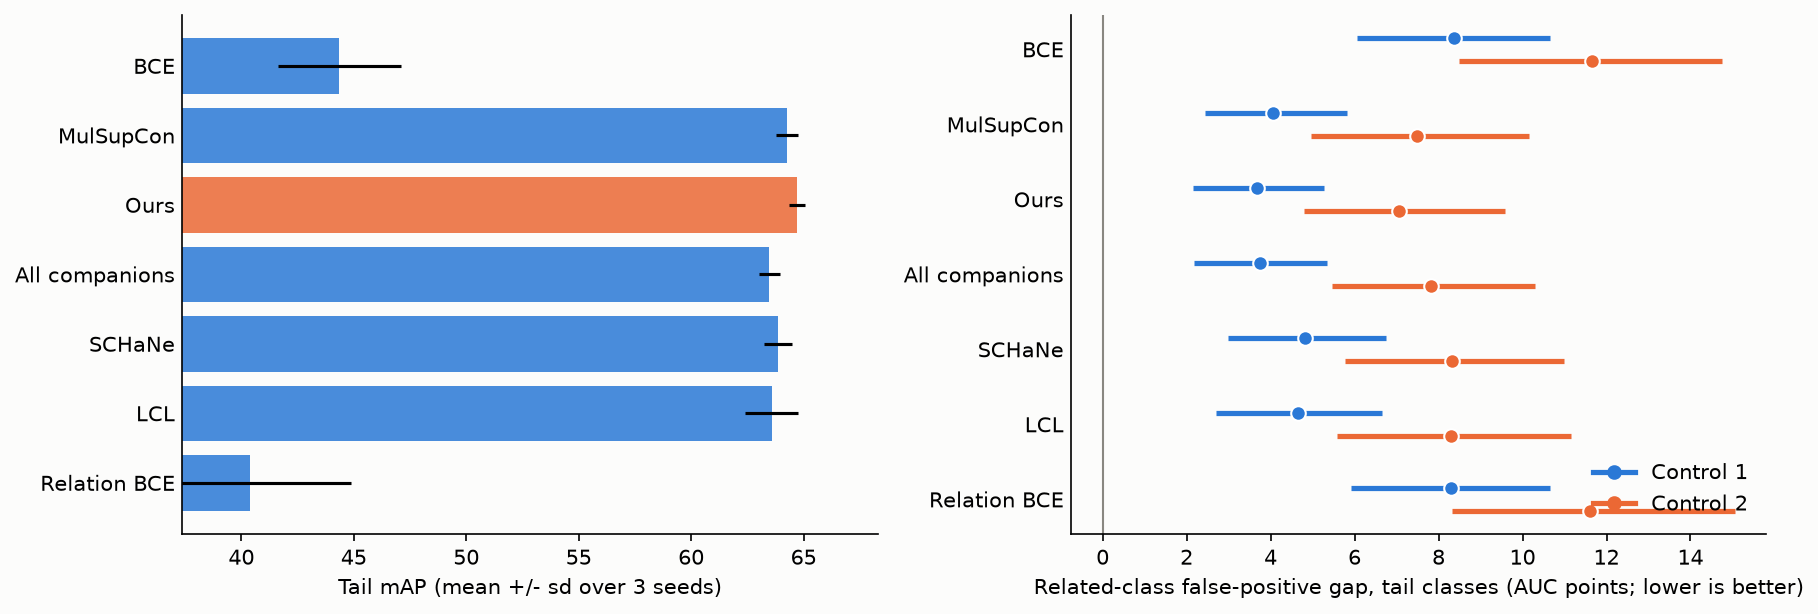

Saved coco_mlt\contrastive\relation_contrastive.png


In [14]:
BLUE, ORANGE, MUTED, SURFACE = "#2a78d6", "#eb6834", "#898781", "#fcfcfb"
order = [k for k, _, _, _ in VARIANTS]
labels_short = {"bce": "BCE", "mulsupcon": "MulSupCon", "ours": "Ours",
                "companions": "All companions", "schane": "SCHaNe",
                "lcl": "LCL", "relbce": "Relation BCE"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), facecolor=SURFACE)
ax = axes[0]
vals = [[100 * np.nanmean(a[TAIL]) for a in AP_SEED["main"][k]] for k in order]
y = np.arange(len(order))[::-1]
ax.barh(y, [np.mean(v) for v in vals],
        xerr=[np.std(v, ddof=1) if len(v) > 1 else 0 for v in vals],
        color=[ORANGE if k == "ours" else BLUE for k in order], alpha=0.85)
ax.set_yticks(y)
ax.set_yticklabels([labels_short[k] for k in order])
ax.set_xlabel("Tail mAP (mean +/- sd over 3 seeds)")
ax.set_xlim(left=max(0, min(np.mean(v) for v in vals) - 3))
ax = axes[1]
for off, col, i in ((0.15, BLUE, 0), (-0.15, ORANGE, 1)):
    for j, k in enumerate(order):
        m, lo, hi, _ = GAP_CI[k][i]
        ax.hlines(y[j] + off, lo, hi, color=col, lw=2.5)
        ax.plot(m, y[j] + off, "o", color=col, ms=7, mec="white")
ax.axvline(0, color=MUTED, lw=1)
ax.set_yticks(y)
ax.set_yticklabels([labels_short[k] for k in order])
ax.set_xlabel("Related-class false-positive gap, tail classes (AUC points; lower is better)")
for a in axes:
    a.set_facecolor(SURFACE)
    for s in ("top", "right"):
        a.spines[s].set_visible(False)
    a.tick_params(axis="y", length=0)
handles = [plt.Line2D([], [], color=BLUE, marker="o", lw=2.5, label="Control 1"),
           plt.Line2D([], [], color=ORANGE, marker="o", lw=2.5, label="Control 2")]
axes[1].legend(handles=handles, frameon=False, loc="lower right")
fig.tight_layout()
FIG = os.path.join(OUT, "relation_contrastive.png")
fig.savefig(FIG, dpi=150, bbox_inches="tight", facecolor=SURFACE)
plt.close(fig)
display(Image(filename=FIG))
print(f"Saved {FIG}")

## Step 12: save the results

In [15]:
results_table.to_csv(os.path.join(OUT, "results.csv"), index=False)
cap30_table.to_csv(os.path.join(OUT, "results_official_30_epoch_cap.csv"),
                   index=False)
comparisons.to_csv(os.path.join(OUT, "comparisons.csv"), index=False)
gap_table.to_csv(os.path.join(OUT, "related_gaps.csv"), index=False)
pd.DataFrame(selection_rows).to_csv(os.path.join(OUT, "selection.csv"), index=False)
per_class = pd.DataFrame({"class": names, "cohort": cohort,
                          **{f"AP {k}": AP["main"][k] for k in AP["main"]}})
per_class.to_csv(os.path.join(OUT, "per_class_ap.csv"), index=False)
with open(os.path.join(OUT, "summary.txt"), "w", encoding="utf-8") as f:
    f.write("\n".join(lines) + "\n\n" + results_table.to_string(index=False)
            + "\n\nOfficial 30-epoch fine-tuning cap:\n"
            + cap30_table.to_string(index=False) + "\n")
print("\n".join(lines))
print(f"\nSaved results.csv, results_official_30_epoch_cap.csv, "
      f"comparisons.csv, related_gaps.csv, selection.csv, per_class_ap.csv "
      f"and summary.txt to {os.path.abspath(OUT)}")

Main result (fine-tuning until early stopping):
  Ours vs MulSupCon: NOT SHOWN  (tail AP improved: False, higher tail mAP in 3 of 3 seeds; related-class gap reduced: False; head AP within 1 point: True)
  Ours vs MulSupCon + SCHaNe weights: NOT SHOWN  (tail AP improved: False, higher tail mAP in 3 of 3 seeds; related-class gap reduced: True; head AP within 1 point: False)
Secondary check (official 30-epoch fine-tuning cap):
  Ours vs MulSupCon: PARTLY  (tail AP improved: True, higher tail mAP in 3 of 3 seeds; related-class gap reduced: False; head AP within 1 point: True)
  Ours vs MulSupCon + all-companion weights: PARTLY  (tail AP improved: True, higher tail mAP in 3 of 3 seeds; related-class gap reduced: False; head AP within 1 point: True)

Saved results.csv, results_official_30_epoch_cap.csv, comparisons.csv, related_gaps.csv, selection.csv, per_class_ap.csv and summary.txt to c:\Users\Admin\pilot-20261029T110719Z-1-001\coco_mlt\contrastive


## How to read the results

- **Step 10** gives the verdict under the rules set at the top. The key
  line is *Ours vs MulSupCon*: same pipeline, only the negative weights
  differ. The secondary check shows whether the verdict depends on the
  fine-tuning budget.
- **Step 8** shows whether tail AP improves and head AP holds; **Step 9**
  whether confusion with related classes drops. A smaller related-class
  gap with no tail AP gain would mean confusion fell but ranking overall
  did not improve.
- *All companions* tests whether being selective matters; *SCHaNe* and
  *LCL* whether the model's own sense of hardness does as well; *Relation
  BCE* whether the contrastive part is needed.

## Limitations

- Frozen CLIP features with an MLP encoder (MulSupCon's vector-data
  setting), not end-to-end image training.
- All variants train on 80% of the training images; the rest is the dev
  set the official protocol needs. Absolute mAP is lower than with all
  images; the comparison between variants is like for like.
- Fine-tuning runs past the official 30-epoch cap (until early
  stopping, at most 400 epochs); the official-cap results are the
  secondary check.
- SCHaNe and LCL have no public code for this setting, so both are
  implemented from their papers' equations inside the MulSupCon loss.
  SCHaNe: Eq. 3 weights on negatives, not detached; its cross-entropy
  term is replaced by the shared BCE fine-tuning. LCL: a weighting
  network trained with BCE (sigmoid, as labels are multi-label), the
  anchor's probability for the negative's labels (the largest over
  them), weights detached, alpha 0.5, and the encoder's own
  classification term left out.
- Each variant's setting is chosen from 1 to 4 values on one seed's dev
  results; three seeds in total.
- The relation types and their 1 / 0.5 / 0.25 weights were motivated by
  diagnostics on these evaluation images, so confirm on a second dataset
  before claiming generality. "Related" comes from CLIP text
  similarity, a noisy stand-in for visual confusability.
- The strongest other variant is picked on the evaluation results,
  which is conservative for our method.
- Runs follow the official code's logic (checked in Step 3), not its
  exact random numbers; GPU arithmetic can differ slightly between runs.